In [1]:
import pandas as pd
import numpy as np
# from vis.utils_motifs import motif_to_fwords
from collections import Counter
import ast
import matplotlib.pyplot as plt
import torch
import math
import seaborn as sns
from pathlib import Path

In [4]:
RESULT_DIR = Path("../results/run_GCN_persuade_wan_cooc_qwen2515b_wan-w5_nf-count+freq+emb_ew-wan_sp-random_L2_H64_sum_lr0.001_seed2026")
features_file = RESULT_DIR / "atobfc010ft.csv"

In [6]:
features_df = pd.read_csv(features_file)
features_df

,feature,feature_name,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference
0,0,feature_0,180,9,0.050000,178,0,0.0,-0.050000
1,2,feature_2,180,4,0.022222,178,0,0.0,-0.022222
2,3,feature_3,180,2,0.011111,178,0,0.0,-0.011111
3,4,feature_4,180,20,0.111111,178,0,0.0,-0.111111
4,6,feature_6,180,3,0.016667,178,0,0.0,-0.016667
...,...,...,...,...,...,...,...,...,...
90,97,feature_97,180,4,0.022222,178,0,0.0,-0.022222
91,98,feature_98,180,5,0.027778,178,0,0.0,-0.027778
92,99,feature_99,180,1,0.005556,178,0,0.0,-0.005556
93,100,feature_100,180,0,0.000000,178,178,1.0,1.000000


In [8]:
df = features_df.copy()

min_present = 10

df = df[
    (df["human_present"] >= min_present)
    & (df["machine_present"] >= min_present)
].copy()

df = df.dropna(subset=["human_rate", "machine_rate"])

df["abs_difference"] = df["difference"].abs()

# Sort by largest difference
df = df.sort_values(
    "abs_difference",
    ascending=False
)

display(df.head(20))

,feature,feature_name,human_present,human_selected,human_rate,machine_present,machine_selected,machine_rate,difference,abs_difference
93,100,feature_100,180,0,0.000000,178,178,1.000000,1.000000,1.000000
51,56,feature_56,180,0,0.000000,178,143,0.803371,0.803371,0.803371
89,96,feature_96,180,161,0.894444,178,18,0.101124,-0.793321,0.793321
63,68,feature_68,180,158,0.877778,178,35,0.196629,-0.681149,0.681149
59,64,feature_64,180,101,0.561111,178,0,0.000000,-0.561111,0.561111
39,42,feature_42,180,79,0.438889,178,178,1.000000,0.561111,0.561111
35,37,feature_37,180,99,0.550000,178,0,0.000000,-0.550000,0.550000
56,61,feature_61,180,1,0.005556,178,78,0.438202,0.432647,0.432647
74,80,feature_80,180,118,0.655556,178,178,1.000000,0.344444,0.344444
46,51,feature_51,180,0,0.000000,178,49,0.275281,0.275281,0.275281


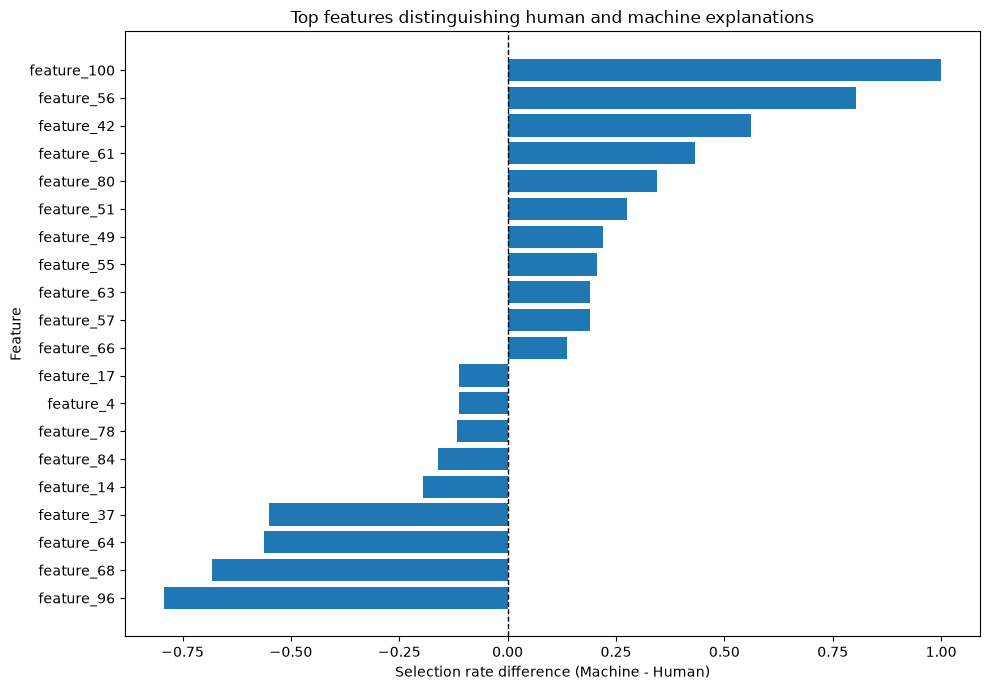

In [9]:
top_n = 20

plot_df = (
    df.nlargest(top_n, "abs_difference")
    .sort_values("difference")
)

fig, ax = plt.subplots(figsize=(10, 7))

ax.barh(
    plot_df["feature_name"],
    plot_df["difference"]
)

ax.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=1
)

ax.set_xlabel(
    "Selection rate difference (Machine - Human)"
)

ax.set_ylabel("Feature")

ax.set_title(
    "Top features distinguishing human and machine explanations"
)

plt.tight_layout()
plt.show()

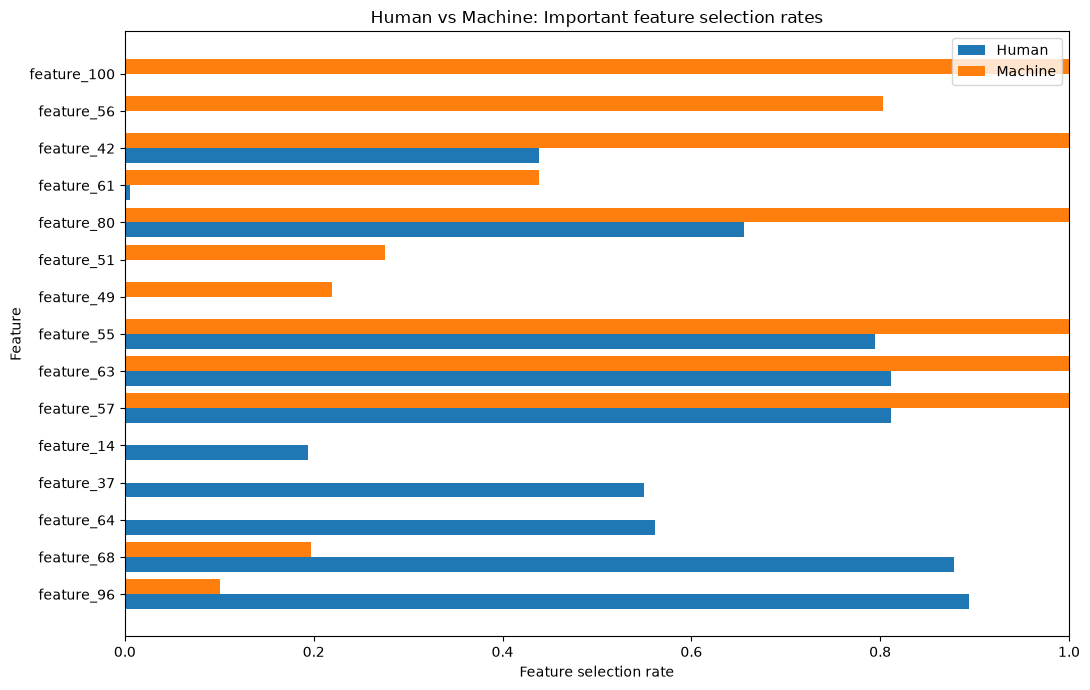

In [10]:
top_n = 15

plot_df = (
    df.nlargest(top_n, "abs_difference")
    .sort_values("difference")
)

y = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(11, 7))

ax.barh(
    y - 0.2,
    plot_df["human_rate"],
    height=0.4,
    label="Human"
)

ax.barh(
    y + 0.2,
    plot_df["machine_rate"],
    height=0.4,
    label="Machine"
)

ax.set_yticks(y)
ax.set_yticklabels(plot_df["feature_name"])

ax.set_xlabel("Feature selection rate")
ax.set_ylabel("Feature")

ax.set_xlim(0, 1)

ax.set_title(
    "Human vs Machine: Important feature selection rates"
)

ax.legend()

plt.tight_layout()
plt.show()

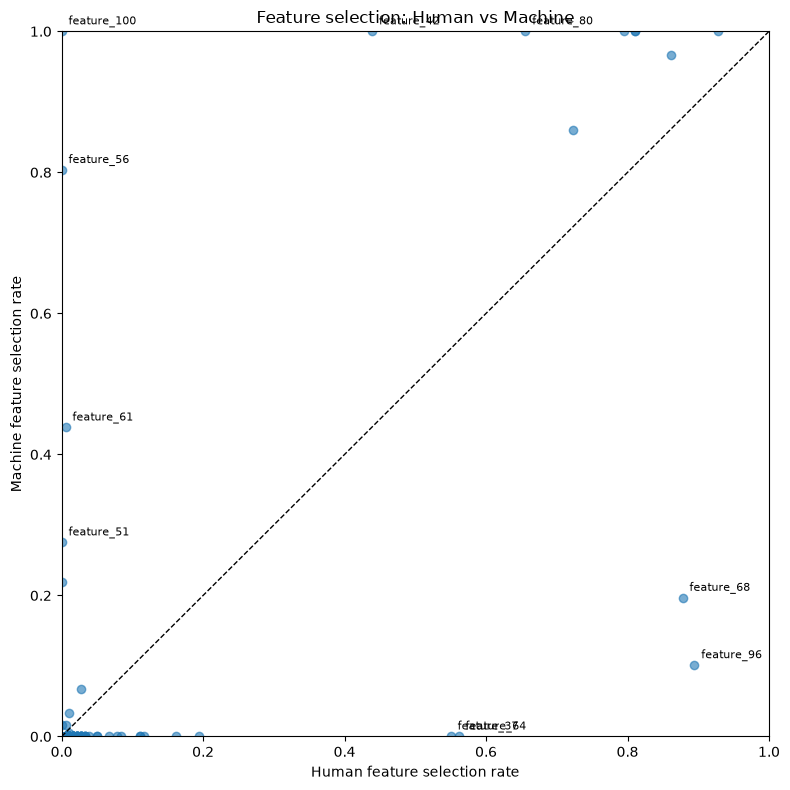

In [11]:
fig, ax = plt.subplots(figsize=(8, 8))

ax.scatter(
    df["human_rate"],
    df["machine_rate"],
    alpha=0.6
)

# Equal-selection line
ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="black",
    linewidth=1
)

# Label features with largest differences
top_features = df.nlargest(10, "abs_difference")

for _, row in top_features.iterrows():

    ax.annotate(
        row["feature_name"],
        (
            row["human_rate"],
            row["machine_rate"]
        ),
        fontsize=8,
        xytext=(5, 5),
        textcoords="offset points"
    )

ax.set_xlim(0, 1)
ax.set_ylim(0, 1)

ax.set_xlabel("Human feature selection rate")
ax.set_ylabel("Machine feature selection rate")

ax.set_title(
    "Feature selection: Human vs Machine"
)

plt.tight_layout()
plt.show()